Implementing micrograd: backpropagation for scalar values (although conceptually and mathematically, things are the same in modern auto differentiation libraries; it's just that things are in tensors instead of scalars)

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

Review of derivatives:

In [2]:
def f(x):
    return 3*x**2 - 5*x + 3

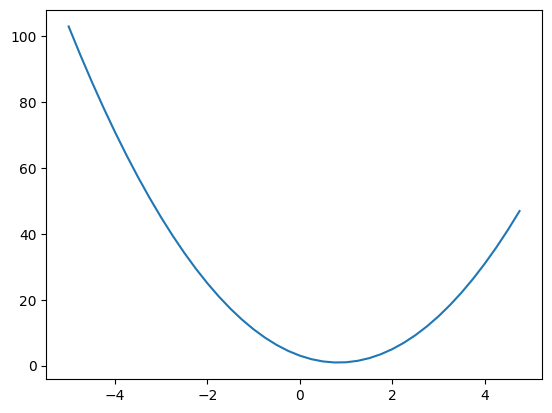

In [3]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [4]:
# definition of derivative
h = 0.00000001
x = 2/3
(f(x+h) - f(x))/h

-1.0000000161269895

In [5]:
# another example
h = 0.0000001

# inputs
a = 3.0
b = -4.0
c = 2.0

d1 = a*b + c
a += h
d2 = a*b + c

print("slope: ", (d2-d1)/h)

slope:  -3.9999999934536845


## Building the core Value object for micrograd.

### Step 0:
- Outline data structure and implement add, multiply, etc. functions

### Step 1 (_prev and _op):
- For each value, we need to know the children values that created that particular value (i.e., we need to know it "children").
- For each value, we need to know the operation that created that value.

This way, for each value, we know exactly how that value came to be: by what values being operated together, and which operation.

### Step 2 (grad):
We need grad, a variable inside the Value class, that maintains the derivative of the final output value wrt a particular value of interest (current value).

### Step 3 (_backward):
We need to implement the function that propagates the gradient. _backward function stores, for each node, how the upstream gradient (coming from final output) should be chained with the downstream gradient (going towards inputs).
Once implemented, at this point, we can manually call _backward for each computational node.

![Gradient flow](fig/backprop.png)

### Step 4 (backward):
Instead of manually calling _backward through all the computational nodes, use topological sort to sort the nodes from left to right, and then call _backwards along those sorted nodes (in reverse order).

### Step 5 (gradient accumulation):
So far, if any variable is used twice, then gradients overwrite, and we get the wrong gradients. We need to allow gradients to accumulate.

### Step 6 (some clean up):
Make it so that things like "a = Value(2.0) ; a + 1 ; 1 + a" work

In [ ]:
class Value:

    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children)
        self._op =_op
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        "__repr__ is used to return a string representation of an object that can be used to essentially recreate the object using eval()"
        return f"Value(data={self.data})"

    def __add__(self, other):
        "when we use 'a + b' in python, python will internally call a.__add__(b)"
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            """
            out.grad is the upstream gradient
            We need to fill in the downstream gradients, i.e., gradients of the inputs to this computational node.
            Here, we apply chain rule, for addition.
            These functions return None.
            """
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        # just store the _backward function
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), "*")
        other = other if isinstance(other, Value) else Value(other)

        def _backward():
            """
            out.grad is the upstream gradient
            We need to fill in the downstream gradients, i.e. gradients of the inputs to this computational node.
            Here, we apply the chain rule, for multiplication.
            These functions return None.
            """
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward

        return out

    def __rmul__(self, other):
        "used to define reversed multiplication"
        return other * self

    def __truediv__(self, other):
        "implements self / other"
        return self * other**-1 

    

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), "exp")

        def _backward():
            self.grad += out.data * out.grad
            
        out._backward = _backward()

        return out

    # NOTE: implementations of local derivatives can be as atomic (e.g., +, -) or as abstract (e.g. tanh) as we want; the most important thing is we know the local derivative
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), "tanh")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
            # only append current value to the topological list once all its children nodes have been added
            topo.append(v)
        
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

Dummy example:

In [19]:
a = Value(2.0)
b = Value (-3.0)
c = Value(10.0)
d = a*b + c

In [20]:
d.backward()

print("dd/dc: ", c.grad)
print("dd/db: ", b.grad)
print("dd/da: ", a.grad)

dd/dc:  1.0
dd/db:  2.0
dd/da:  -3.0


Example that requires gradient accumulation:
- In the above examples, each variable was only used once. In the following case, the variable a, for example, is used twice: in c = a * b, and in d = a * b.
- In the original code, there was a bug where inside the backward implementation we SET gradients, instead of accumulating gradients: e.g., self.grad = out.grad * other.data
- This creates a problem when we call e.backward(). The backward pass triggers calling ._backward() at each computational node. For example, at c._backward(), the gradient is set for a, but then later on when d._backward() is called, the gradient is overwritten for a and set again at another value.
- According to the multivariate chain rule, these gradients need to ACCUMULATE:
    - If z = f(x, y), where x = g(t) and y = h(t) depend on a single independent variable t, the total derivative of z with respect to t is: dz/dt = df/dx * dx/dt + df/dy * dy/dt
    - You sum the products of the partial derivatives of f with respect to each intermediate variable, multiplied by the derivative of that intermediate variable with respect to t.
    - So in this example, to compute a.grad (for e.backward()), we would do: de/dc * dc/da + de/dd * dd/da
    - Notice, how we add, and these gradients accumulate.
- This is why we implement gradients as: e.g., self.grad += out.grad * other.data
- This is ok, because we initialize a value's grad to 0. So they accumulate starting from zero.

In [22]:
a = Value(-2.0)
b = Value(3.0)
c = a + b
d = a * b
e = c * d

e.backward()

b.grad

-8.0